In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow joblib

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

from sklearn.inspection import permutation_importance

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

import joblib
import warnings

warnings.filterwarnings("ignore")

np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
df.head()
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


In [5]:
df.info()
df.describe()
print("Missing values in each column:")

print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)

print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

TotalCharges data type: float64
Missing TotalCharges: 11


In [8]:
df = df.drop("customerID", axis=1)

print("CustomerID column removed.")
print("Updated dataset shape:", df.shape)

CustomerID column removed.
Updated dataset shape: (7043, 20)


In [9]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [10]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Customer Churn Distribution:")

print(churn_percentage)

Customer Churn Distribution:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


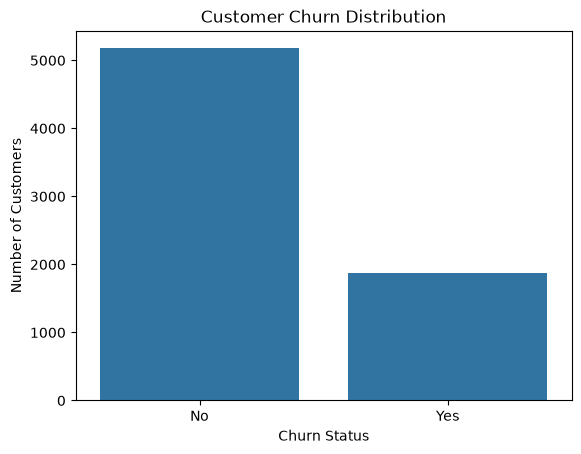

In [11]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [12]:
X = df.drop("Churn", axis=1)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (7043, 19)
Target shape: (7043,)


In [13]:
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [14]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (4225, 19)
Validation data: (1409, 19)
Testing data: (1409, 19)


In [15]:
total_records = len(df)

print("Training percentage:", len(X_train) / total_records * 100)

print("Validation percentage:", len(X_val) / total_records * 100)

print("Testing percentage:", len(X_test) / total_records * 100)

Training percentage: 59.988641204032376
Validation percentage: 20.005679397983815
Testing percentage: 20.005679397983815


In [16]:
print("Training churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation churn distribution:")
print(y_val.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training churn distribution:
Churn
0    73.467456
1    26.532544
Name: proportion, dtype: float64

Validation churn distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [17]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

In [18]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)

print("Validation processed shape:", X_val_processed.shape)

print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (4225, 45)
Validation processed shape: (1409, 45)
Testing processed shape: (1409, 45)


In [19]:
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_val_processed, "toarray"):
    X_val_processed = X_val_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

print("Training data shape:", X_train_processed.shape)

print("Validation data shape:", X_val_processed.shape)

print("Testing data shape:", X_test_processed.shape)

Training data shape: (4225, 45)
Validation data shape: (1409, 45)
Testing data shape: (1409, 45)


In [20]:
def calculate_metrics(y_actual, y_predicted):

    accuracy = accuracy_score(y_actual, y_predicted)

    precision = precision_score(y_actual, y_predicted, zero_division=0)

    recall = recall_score(y_actual, y_predicted, zero_division=0)

    f1 = f1_score(y_actual, y_predicted, zero_division=0)

    return accuracy, precision, recall, f1

In [21]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [22]:
logistic_predictions = logistic_model.predict(X_val_processed)

logistic_accuracy, logistic_precision, logistic_recall, logistic_f1 = calculate_metrics(
    y_val,
    logistic_predictions
)

print("Logistic Regression Results")

print("Accuracy:", logistic_accuracy)

print("Precision:", logistic_precision)

print("Recall:", logistic_recall)

print("F1 Score:", logistic_f1)

Logistic Regression Results
Accuracy: 0.8239886444286728
Precision: 0.6981132075471698
Recall: 0.5935828877005348
F1 Score: 0.6416184971098265


In [23]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

random_forest_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest training completed!")

Random Forest training completed!


In [24]:
rf_predictions = random_forest_model.predict(X_val_processed)

rf_accuracy, rf_precision, rf_recall, rf_f1 = calculate_metrics(
    y_val,
    rf_predictions
)

print("Random Forest Results")

print("Accuracy:", rf_accuracy)

print("Precision:", rf_precision)

print("Recall:", rf_recall)

print("F1 Score:", rf_f1)

Random Forest Results
Accuracy: 0.7835344215755855
Precision: 0.5856079404466501
Recall: 0.6310160427807486
F1 Score: 0.6074646074646075


In [25]:
baseline_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],

    "Precision": [
        logistic_precision,
        rf_precision
    ],

    "Recall": [
        logistic_recall,
        rf_recall
    ],

    "F1 Score": [
        logistic_f1,
        rf_f1
    ]

})

baseline_results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.823989,0.698113,0.593583,0.641618
1,Random Forest,0.783534,0.585608,0.631016,0.607465


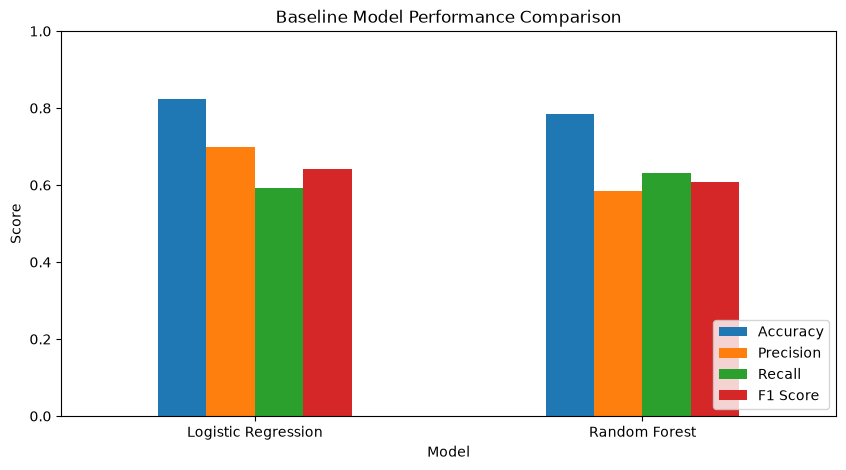

In [26]:
baseline_results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Baseline Model Performance Comparison")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.show()

In [27]:
input_features = X_train_processed.shape[1]

neural_model = Sequential([

    Dense(
        64,
        activation="relu",
        input_shape=(input_features,)
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )

])

print(neural_model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,057 (19.75 KB)

 Trainable params: 5,057 (19.75 KB)

 Non-trainable params: 0 (0.00 B)

None


In [28]:
neural_model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

print("Neural network compiled successfully!")

Neural network compiled successfully!


In [29]:
history = neural_model.fit(

    X_train_processed,
    y_train,

    validation_data=(
        X_val_processed,
        y_val
    ),

    epochs=50,

    batch_size=32,

    verbose=1

)

Epoch 1/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.7605 - loss: 0.4771 - val_accuracy: 0.8112 - val_loss: 0.4109
Epoch 2/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8014 - loss: 0.4222 - val_accuracy: 0.8183 - val_loss: 0.4055
Epoch 3/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8059 - loss: 0.4165 - val_accuracy: 0.8141 - val_loss: 0.4043
Epoch 4/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8071 - loss: 0.4126 - val_accuracy: 0.8169 - val_loss: 0.4038
Epoch 5/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8088 - loss: 0.4099 - val_accuracy: 0.8169 - val_loss: 0.4037
Epoch 6/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8088 - loss: 0.4073 - val_accuracy: 0.8133 - val_loss: 0.4037
Epoch 7/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8090 - loss: 0.4049 - val_accuracy: 0.8112 - val_loss: 0.4034
Epoch 8/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8104 - loss: 0.4026 - val_accuracy: 0

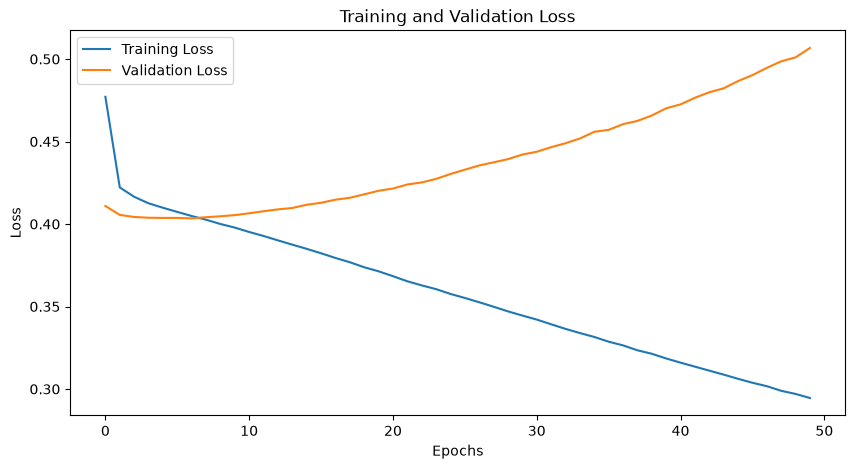

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.show()

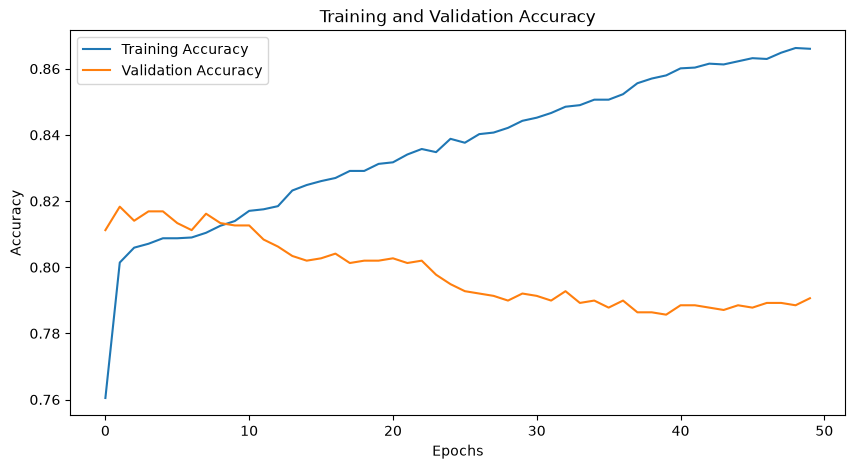

In [31]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

In [32]:
nn_probabilities = neural_model.predict(
    X_val_processed
)

nn_predictions = (
    nn_probabilities >= 0.5
).astype(int).flatten()

nn_accuracy, nn_precision, nn_recall, nn_f1 = calculate_metrics(
    y_val,
    nn_predictions
)

print("Basic Neural Network Results")

print("Accuracy:", nn_accuracy)

print("Precision:", nn_precision)

print("Recall:", nn_recall)

print("F1 Score:", nn_f1)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Basic Neural Network Results
Accuracy: 0.7906316536550745
Precision: 0.6348122866894198
Recall: 0.49732620320855614
F1 Score: 0.5577211394302849


In [33]:
def create_neural_network(dropout_rate, l2_rate):

    model = Sequential([

        Dense(
            64,
            activation="relu",
            kernel_regularizer=l2(l2_rate),
            input_shape=(input_features,)
        ),

        Dropout(dropout_rate),

        Dense(
            32,
            activation="relu",
            kernel_regularizer=l2(l2_rate)
        ),

        Dropout(dropout_rate),

        Dense(
            1,
            activation="sigmoid"
        )

    ])

    model.compile(

        optimizer="adam",

        loss="binary_crossentropy",

        metrics=["accuracy"]

    )

    return model

In [34]:
early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True

)

print("Early stopping configured successfully!")

Early stopping configured successfully!


In [35]:
dropout_values = [0.2, 0.3, 0.5]

l2_values = [0.001, 0.01, 0.1]

experiment_results = []

best_model = None

best_history = None

best_f1 = -1

best_dropout = None

best_l2 = None

for dropout_rate in dropout_values:

    for l2_rate in l2_values:

        print(
            "Testing Dropout:",
            dropout_rate,
            "L2:",
            l2_rate
        )

        tf.keras.backend.clear_session()

        model = create_neural_network(
            dropout_rate,
            l2_rate
        )

        history_exp = model.fit(

            X_train_processed,
            y_train,

            validation_data=(
                X_val_processed,
                y_val
            ),

            epochs=50,

            batch_size=32,

            callbacks=[early_stopping],

            verbose=0

        )

        probabilities = model.predict(
            X_val_processed,
            verbose=0
        )

        predictions = (
            probabilities >= 0.5
        ).astype(int).flatten()

        accuracy, precision, recall, f1 = calculate_metrics(
            y_val,
            predictions
        )

        experiment_results.append({

            "Dropout": dropout_rate,

            "L2": l2_rate,

            "Epochs": len(history_exp.history["loss"]),

            "Accuracy": accuracy,

            "Precision": precision,

            "Recall": recall,

            "F1 Score": f1

        })

        if f1 > best_f1:

            best_f1 = f1

            best_model = model

            best_history = history_exp

            best_dropout = dropout_rate

            best_l2 = l2_rate

print("\nAll experiments completed!")

Testing Dropout: 0.2 L2: 0.001

Testing Dropout: 0.2 L2: 0.01
Testing Dropout: 0.2 L2: 0.1
Testing Dropout: 0.3 L2: 0.001
Testing Dropout: 0.3 L2: 0.01
Testing Dropout: 0.3 L2: 0.1
Testing Dropout: 0.5 L2: 0.001
Testing Dropout: 0.5 L2: 0.01
Testing Dropout: 0.5 L2: 0.1

All experiments completed!


In [36]:
experiment_df = pd.DataFrame(experiment_results)

experiment_df = experiment_df.sort_values(
    by="F1 Score",
    ascending=False
)

experiment_df

,Dropout,L2,Epochs,Accuracy,Precision,Recall,F1 Score
6,0.5,0.001,46,0.816182,0.679128,0.582888,0.627338
3,0.3,0.001,38,0.812633,0.672956,0.572193,0.618497
4,0.3,0.010,39,0.817601,0.698305,0.550802,0.615845
1,0.2,0.010,46,0.821150,0.719424,0.534759,0.613497
0,0.2,0.001,34,0.812633,0.678571,0.558824,0.612903
7,0.5,0.010,34,0.816182,0.694915,0.548128,0.612855
2,0.2,0.100,49,0.800568,0.743455,0.379679,0.502655
5,0.3,0.100,50,0.801278,0.755435,0.371658,0.498208
8,0.5,0.100,49,0.790632,0.758170,0.310160,0.440228


In [37]:
print("Best Neural Network Configuration")

print("Dropout Rate:", best_dropout)

print("L2 Regularization:", best_l2)

print("Best Validation F1 Score:", best_f1)

Best Neural Network Configuration
Dropout Rate: 0.5
L2 Regularization: 0.001
Best Validation F1 Score: 0.6273381294964029


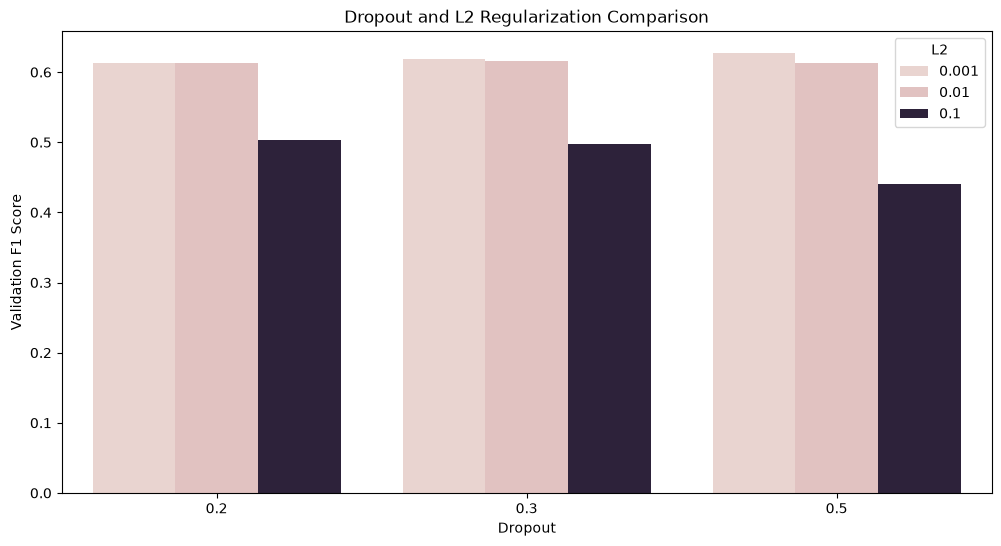

In [38]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=experiment_df,
    x="Dropout",
    y="F1 Score",
    hue="L2"
)

plt.title("Dropout and L2 Regularization Comparison")

plt.ylabel("Validation F1 Score")

plt.show()

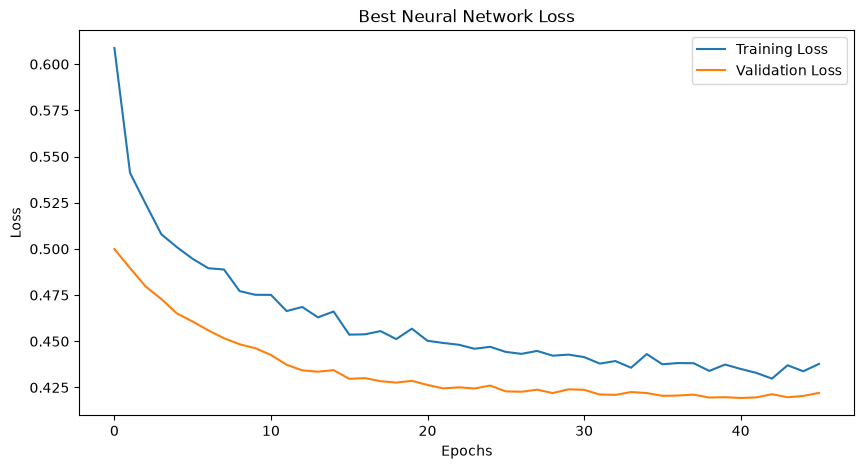

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(
    best_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    best_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Best Neural Network Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [40]:
best_val_probabilities = best_model.predict(
    X_val_processed
)

best_val_predictions = (
    best_val_probabilities >= 0.5
).astype(int).flatten()

print("Best Neural Network Validation Results")

print(
    classification_report(
        y_val,
        best_val_predictions
    )
)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Best Neural Network Validation Results
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1035
           1       0.68      0.58      0.63       374

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.82      0.81      1409



In [41]:
logistic_test_predictions = logistic_model.predict(
    X_test_processed
)

print("Logistic Regression test predictions completed.")

Logistic Regression test predictions completed.


In [42]:
rf_test_predictions = random_forest_model.predict(
    X_test_processed
)

print("Random Forest test predictions completed.")

Random Forest test predictions completed.


In [43]:
nn_test_probabilities = best_model.predict(
    X_test_processed
)

nn_test_predictions = (
    nn_test_probabilities >= 0.5
).astype(int).flatten()

print("Neural Network test predictions completed.")

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Neural Network test predictions completed.


In [44]:
logistic_test_metrics = calculate_metrics(
    y_test,
    logistic_test_predictions
)

rf_test_metrics = calculate_metrics(
    y_test,
    rf_test_predictions
)

nn_test_metrics = calculate_metrics(
    y_test,
    nn_test_predictions
)

print("All model predictions evaluated successfully!")

All model predictions evaluated successfully!


In [45]:
comparison_df = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Neural Network"
    ],

    "Accuracy": [
        logistic_test_metrics[0],
        rf_test_metrics[0],
        nn_test_metrics[0]
    ],

    "Precision": [
        logistic_test_metrics[1],
        rf_test_metrics[1],
        nn_test_metrics[1]
    ],

    "Recall": [
        logistic_test_metrics[2],
        rf_test_metrics[2],
        nn_test_metrics[2]
    ],

    "F1 Score": [
        logistic_test_metrics[3],
        rf_test_metrics[3],
        nn_test_metrics[3]
    ]

})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.787793,0.617555,0.526738,0.568543
1,Random Forest,0.761533,0.544601,0.620321,0.580000
2,Neural Network,0.784954,0.610592,0.524064,0.564029


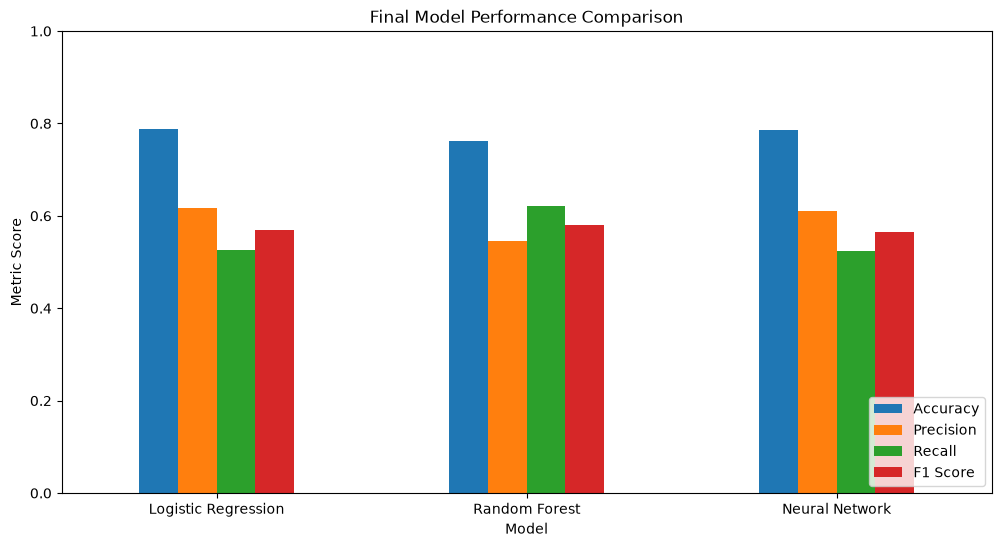

In [47]:
comparison_df.set_index("Model").plot(

    kind="bar",

    figsize=(12, 6)

)

plt.title("Final Model Performance Comparison")

plt.ylabel("Metric Score")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.show()

In [48]:
best_model_name = comparison_df.loc[
    comparison_df["F1 Score"].idxmax(),
    "Model"
]

print("Best Model Based on Test F1 Score:", best_model_name)

Best Model Based on Test F1 Score: Random Forest


In [49]:
print("LOGISTIC REGRESSION")

print(
    classification_report(
        y_test,
        logistic_test_predictions
    )
)

print("\nRANDOM FOREST")

print(
    classification_report(
        y_test,
        rf_test_predictions
    )
)

print("\nNEURAL NETWORK")

print(
    classification_report(
        y_test,
        nn_test_predictions
    )
)

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.62      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409


RANDOM FOREST
              precision    recall  f1-score   support

           0       0.86      0.81      0.83      1035
           1       0.54      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409


NEURAL NETWORK
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.61      0.52      0.56       374

    accuracy                           0.78      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.78

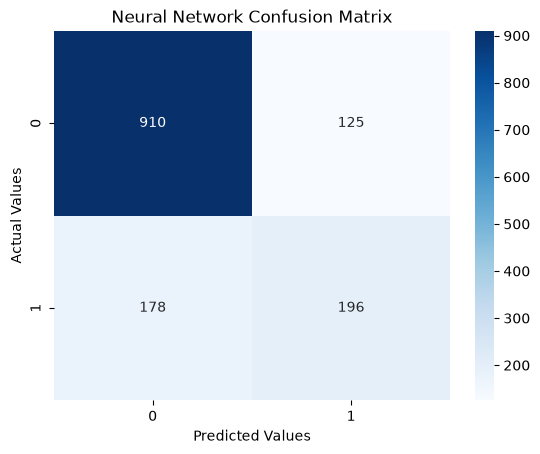

In [50]:
cm = confusion_matrix(
    y_test,
    nn_test_predictions
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Neural Network Confusion Matrix")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.show()

In [51]:
logistic_test_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

rf_test_probabilities = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

logistic_auc = roc_auc_score(
    y_test,
    logistic_test_probabilities
)

rf_auc = roc_auc_score(
    y_test,
    rf_test_probabilities
)

nn_auc = roc_auc_score(
    y_test,
    nn_test_probabilities.flatten()
)

print("Logistic Regression ROC-AUC:", logistic_auc)

print("Random Forest ROC-AUC:", rf_auc)

print("Neural Network ROC-AUC:", nn_auc)

Logistic Regression ROC-AUC: 0.832444651114728
Random Forest ROC-AUC: 0.803554728874422
Neural Network ROC-AUC: 0.8307163708698236


In [52]:
comparison_df["ROC-AUC"] = [

    logistic_auc,

    rf_auc,

    nn_auc

]

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.787793,0.617555,0.526738,0.568543,0.832445
1,Random Forest,0.761533,0.544601,0.620321,0.580000,0.803555
2,Neural Network,0.784954,0.610592,0.524064,0.564029,0.830716


In [53]:
customer_results = X_test.copy()

customer_results["Actual_Churn"] = y_test.values

customer_results["Churn_Probability"] = (
    nn_test_probabilities.flatten()
)

customer_results["Predicted_Churn"] = (
    nn_test_predictions
)

customer_results = customer_results.sort_values(
    by="Churn_Probability",
    ascending=False
)

customer_results.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.861555,1
6894,Male,1,Yes,No,3,Yes,Yes,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Electronic check,105.90,334.65,1,0.846530,1
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,0.840991,1
6365,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,0.834853,1
4800,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,94.00,94.00,1,0.831996,1
3085,Male,0,No,No,3,Yes,Yes,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),105.35,323.25,1,0.823591,1
6317,Male,0,No,No,1,Yes,Yes,Fiber optic,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,79.15,79.15,1,0.818492,1
1880,Male,0,No,No,2,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,86.00,165.45,1,0.816899,1
1561,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,74.95,74.95,1,0.814400,1
777,Male,0,No,No,2,Yes,Yes,Fiber optic,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,82.00,184.65,1,0.814386,1


In [54]:
high_risk_customers = customer_results[
    customer_results["Churn_Probability"] >= 0.70
]

print(
    "Number of high-risk customers:",
    len(high_risk_customers)
)

high_risk_customers.head(10)

Number of high-risk customers: 92


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.861555,1
6894,Male,1,Yes,No,3,Yes,Yes,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Electronic check,105.90,334.65,1,0.846530,1
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,0.840991,1
6365,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,0.834853,1
4800,Male,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,94.00,94.00,1,0.831996,1
3085,Male,0,No,No,3,Yes,Yes,Fiber optic,No,Yes,...,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),105.35,323.25,1,0.823591,1
6317,Male,0,No,No,1,Yes,Yes,Fiber optic,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,79.15,79.15,1,0.818492,1
1880,Male,0,No,No,2,Yes,Yes,Fiber optic,No,No,...,No,Yes,Month-to-month,Yes,Electronic check,86.00,165.45,1,0.816899,1
1561,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,74.95,74.95,1,0.814400,1
777,Male,0,No,No,2,Yes,Yes,Fiber optic,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,82.00,184.65,1,0.814386,1


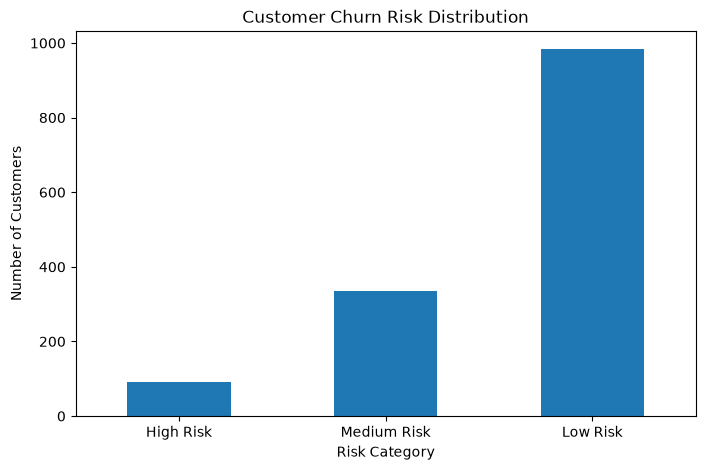

In [55]:
risk_counts = pd.Series({

    "High Risk": (
        customer_results["Churn_Probability"] >= 0.70
    ).sum(),

    "Medium Risk": (
        (customer_results["Churn_Probability"] >= 0.40) &
        (customer_results["Churn_Probability"] < 0.70)
    ).sum(),

    "Low Risk": (
        customer_results["Churn_Probability"] < 0.40
    ).sum()

})

risk_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Churn Risk Distribution")

plt.xlabel("Risk Category")

plt.ylabel("Number of Customers")

plt.xticks(rotation=0)

plt.show()

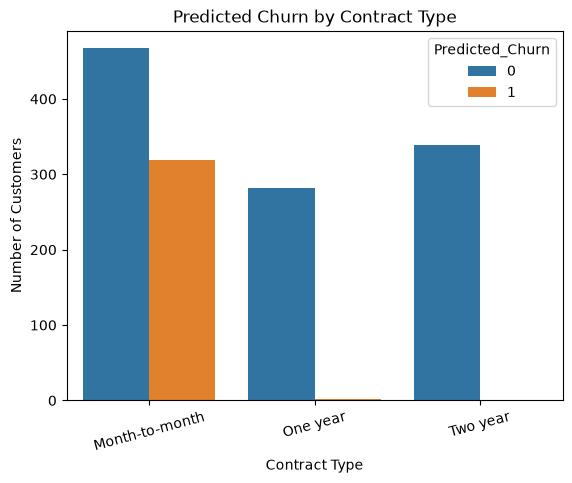

In [56]:
sns.countplot(
    data=customer_results,
    x="Contract",
    hue="Predicted_Churn"
)

plt.title("Predicted Churn by Contract Type")

plt.xlabel("Contract Type")

plt.ylabel("Number of Customers")

plt.xticks(rotation=15)

plt.show()

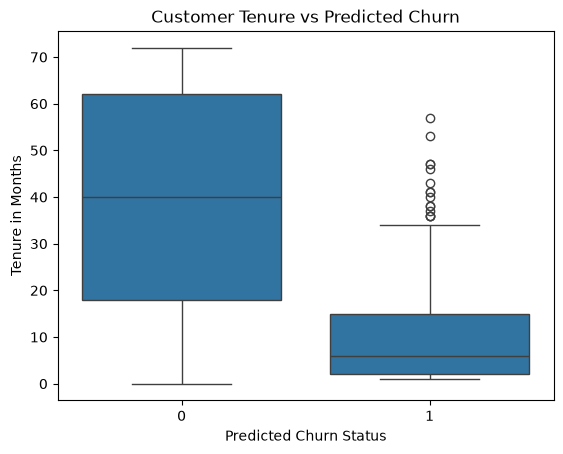

In [57]:
sns.boxplot(
    data=customer_results,
    x="Predicted_Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Predicted Churn")

plt.xlabel("Predicted Churn Status")

plt.ylabel("Tenure in Months")

plt.show()

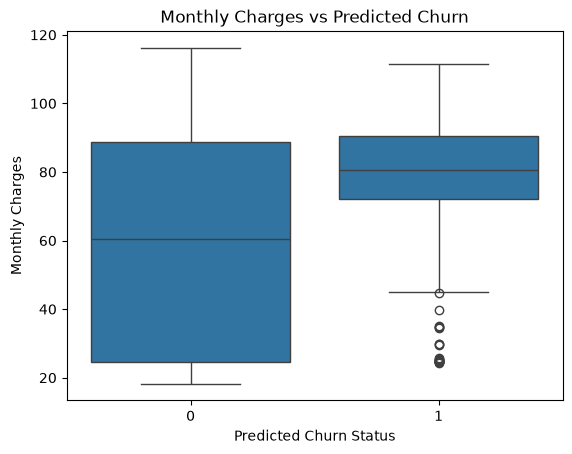

In [58]:
sns.boxplot(
    data=customer_results,
    x="Predicted_Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Predicted Churn")

plt.xlabel("Predicted Churn Status")

plt.ylabel("Monthly Charges")

plt.show()

In [59]:
feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))

print(feature_names)

Total processed features: 45
['numerical__SeniorCitizen' 'numerical__tenure'
 'numerical__MonthlyCharges' 'numerical__TotalCharges'
 'categorical__gender_Female' 'categorical__gender_Male'
 'categorical__Partner_No' 'categorical__Partner_Yes'
 'categorical__Dependents_No' 'categorical__Dependents_Yes'
 'categorical__PhoneService_No' 'categorical__PhoneService_Yes'
 'categorical__MultipleLines_No'
 'categorical__MultipleLines_No phone service'
 'categorical__MultipleLines_Yes' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes' 'categorical__OnlineBackup_No'
 'categorical__OnlineBackup_No internet service'
 'categorical__OnlineBackup_Yes' 'categorical__DeviceProtection_No'
 'categorical__DeviceProtection_No internet service'
 'categorical__DeviceProtection_Yes' 'categorical__TechSupport_No'
 'categorical__Tec

In [60]:
rf_importance = permutation_importance(

    random_forest_model,

    X_test_processed,

    y_test,

    n_repeats=5,

    random_state=42,

    scoring="roc_auc"

)

rf_importance_df = pd.DataFrame({

    "Feature": feature_names,

    "Importance": rf_importance.importances_mean

})

rf_importance_df = rf_importance_df.sort_values(

    by="Importance",

    ascending=False

)

rf_importance_df.head(15)

,Feature,Importance
1,numerical__tenure,0.019935
36,categorical__Contract_Month-to-month,0.015922
38,categorical__Contract_Two year,0.010678
3,numerical__TotalCharges,0.009587
16,categorical__InternetService_Fiber optic,0.008610
18,categorical__OnlineSecurity_No,0.002275
15,categorical__InternetService_DSL,0.001750
37,categorical__Contract_One year,0.001277
43,categorical__PaymentMethod_Electronic check,0.000702
0,numerical__SeniorCitizen,0.000682


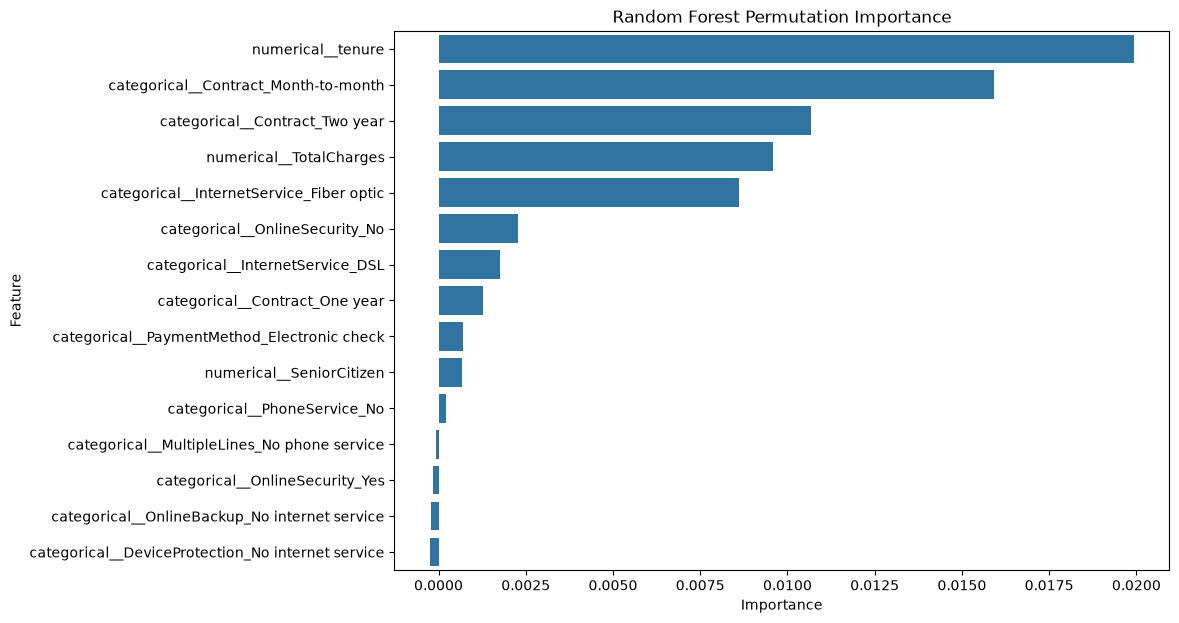

In [61]:
plt.figure(figsize=(10, 7))

sns.barplot(

    data=rf_importance_df.head(15),

    x="Importance",

    y="Feature"

)

plt.title("Random Forest Permutation Importance")

plt.show()

In [62]:
original_nn_auc = roc_auc_score(

    y_test,

    best_model.predict(
        X_test_processed,
        verbose=0
    ).flatten()

)

nn_importance_values = []

for i in range(X_test_processed.shape[1]):

    shuffled_data = X_test_processed.copy()

    np.random.seed(42)

    np.random.shuffle(
        shuffled_data[:, i]
    )

    shuffled_probabilities = best_model.predict(

        shuffled_data,

        verbose=0

    ).flatten()

    shuffled_auc = roc_auc_score(

        y_test,

        shuffled_probabilities

    )

    importance = original_nn_auc - shuffled_auc

    nn_importance_values.append(importance)

print("Neural Network importance calculated!")

Neural Network importance calculated!


In [63]:
nn_importance_df = pd.DataFrame({

    "Feature": feature_names,

    "Importance": nn_importance_values

})

nn_importance_df = nn_importance_df.sort_values(

    by="Importance",

    ascending=False

)

nn_importance_df.head(15)

,Feature,Importance
1,numerical__tenure,0.074109
36,categorical__Contract_Month-to-month,0.013248
2,numerical__MonthlyCharges,0.011124
38,categorical__Contract_Two year,0.010179
3,numerical__TotalCharges,0.004642
15,categorical__InternetService_DSL,0.004079
20,categorical__OnlineSecurity_Yes,0.002955
16,categorical__InternetService_Fiber optic,0.002506
9,categorical__Dependents_Yes,0.001860
43,categorical__PaymentMethod_Electronic check,0.001847


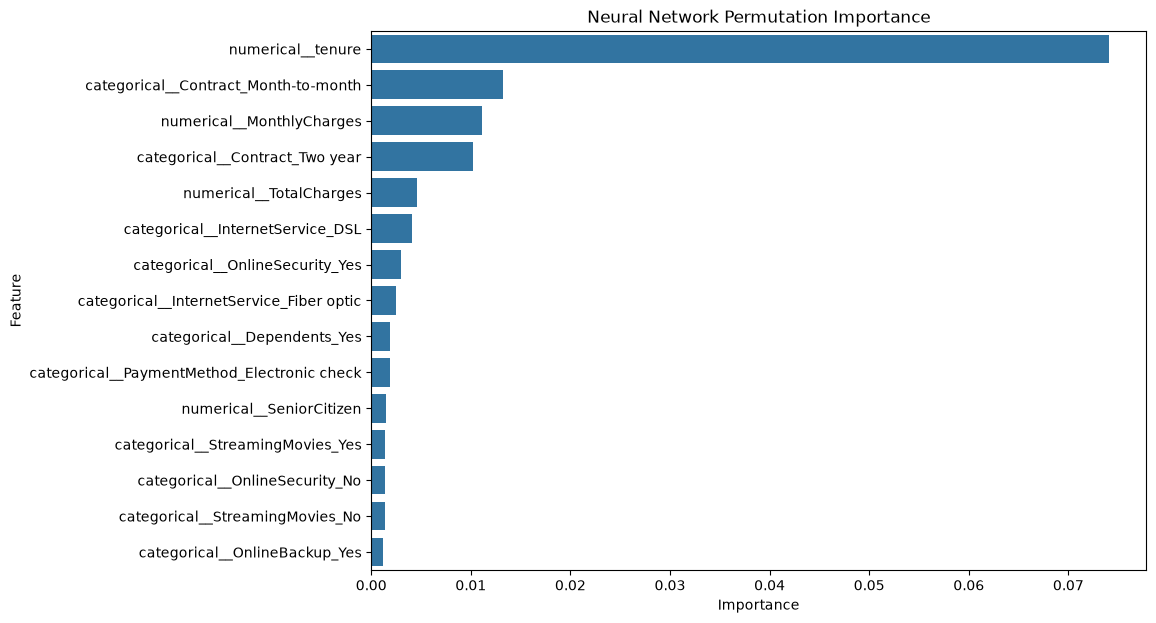

In [64]:
plt.figure(figsize=(10, 7))

sns.barplot(

    data=nn_importance_df.head(15),

    x="Importance",

    y="Feature"

)

plt.title("Neural Network Permutation Importance")

plt.show()

In [65]:
rf_top_features = rf_importance_df.head(10)[
    ["Feature", "Importance"]
].rename({

    "Importance": "Random Forest"

}, axis=1)

nn_top_features = nn_importance_df.head(10)[
    ["Feature", "Importance"]
].rename({

    "Importance": "Neural Network"

}, axis=1)

feature_comparison = pd.merge(

    rf_top_features,

    nn_top_features,

    on="Feature",

    how="outer"

).fillna(0)

feature_comparison

,Feature,Random Forest,Neural Network
0,categorical__Contract_Month-to-month,0.015922,0.013248
1,categorical__Contract_One year,0.001277,0.000000
2,categorical__Contract_Two year,0.010678,0.010179
3,categorical__Dependents_Yes,0.000000,0.001860
4,categorical__InternetService_DSL,0.001750,0.004079
5,categorical__InternetService_Fiber optic,0.008610,0.002506
6,categorical__OnlineSecurity_No,0.002275,0.000000
7,categorical__OnlineSecurity_Yes,0.000000,0.002955
8,categorical__PaymentMethod_Electronic check,0.000702,0.001847
9,numerical__MonthlyCharges,0.000000,0.011124


In [66]:
print("Top 5 Random Forest Features:")

print(
    rf_importance_df.head(5)
)

print("\nTop 5 Neural Network Features:")

print(
    nn_importance_df.head(5)
)

Top 5 Random Forest Features:
                                     Feature  Importance
1                          numerical__tenure    0.019935
36      categorical__Contract_Month-to-month    0.015922
38            categorical__Contract_Two year    0.010678
3                    numerical__TotalCharges    0.009587
16  categorical__InternetService_Fiber optic    0.008610

Top 5 Neural Network Features:
                                 Feature  Importance
1                      numerical__tenure    0.074109
36  categorical__Contract_Month-to-month    0.013248
2              numerical__MonthlyCharges    0.011124
38        categorical__Contract_Two year    0.010179
3                numerical__TotalCharges    0.004642


In [67]:
top_rf_feature = rf_importance_df.iloc[0]["Feature"]

top_nn_feature = nn_importance_df.iloc[0]["Feature"]

print("BUSINESS INSIGHTS")

print("\nMost Important Random Forest Feature:")

print(top_rf_feature)

print("\nMost Important Neural Network Feature:")

print(top_nn_feature)

print("\nBUSINESS RECOMMENDATIONS")

print("1. Identify customers with high churn probability and contact them with personalized retention offers.")

print("2. Analyze important customer features and improve services or pricing based on customer needs.")

print("3. Provide loyalty benefits, discounts and better customer support to customers who are likely to leave.")

BUSINESS INSIGHTS

Most Important Random Forest Feature:
numerical__tenure

Most Important Neural Network Feature:
numerical__tenure

BUSINESS RECOMMENDATIONS
1. Identify customers with high churn probability and contact them with personalized retention offers.
2. Analyze important customer features and improve services or pricing based on customer needs.
3. Provide loyalty benefits, discounts and better customer support to customers who are likely to leave.


In [68]:
best_model.save("best_churn_neural_network.keras")

print("Neural Network saved successfully!")

Neural Network saved successfully!


In [69]:
joblib.dump(
    random_forest_model,
    "random_forest_churn.pkl"
)

joblib.dump(
    logistic_model,
    "logistic_regression_churn.pkl"
)

print("Machine learning models saved successfully!")

Machine learning models saved successfully!


In [70]:
joblib.dump(
    preprocessor,
    "churn_preprocessor.pkl"
)

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


In [71]:
comparison_df.to_csv(
    "churn_model_comparison.csv",
    index=False
)

experiment_df.to_csv(
    "churn_regularization_experiments.csv",
    index=False
)

rf_importance_df.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

nn_importance_df.to_csv(
    "neural_network_feature_importance.csv",
    index=False
)

print("All results saved successfully!")

All results saved successfully!


In [74]:


print("\nDataset Records:", len(df))

print("Training Records:", len(X_train))

print("Validation Records:", len(X_val))

print("Testing Records:", len(X_test))

print("\nBest Neural Network Configuration")

print("Dropout:", best_dropout)

print("L2:", best_l2)

print("\nFinal Model Comparison")

print(comparison_df)

print("\nTop 5 Important Features")

print(rf_importance_df.head(5))






Dataset Records: 7043
Training Records: 4225
Validation Records: 1409
Testing Records: 1409

Best Neural Network Configuration
Dropout: 0.5
L2: 0.001

Final Model Comparison
                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.787793   0.617555  0.526738  0.568543  0.832445
1        Random Forest  0.761533   0.544601  0.620321  0.580000  0.803555
2       Neural Network  0.784954   0.610592  0.524064  0.564029  0.830716

Top 5 Important Features
                                     Feature  Importance
1                          numerical__tenure    0.019935
36      categorical__Contract_Month-to-month    0.015922
38            categorical__Contract_Two year    0.010678
3                    numerical__TotalCharges    0.009587
16  categorical__InternetService_Fiber optic    0.008610
